# 03 — Error analysis: why retrieval misses

Reads the files written by `make b2-analysis`:

- `results/bm25_rescues.csv`: questions where **BM25 finds every gold fact in the top 10 and dense
  does not**. This list is a protocol output: it is the concrete argument for hybrid search.
- `results/failure_modes.csv`: for every query, *why* it missed (definitions below).
  **Exploratory**: this taxonomy was defined after the results were seen, so it describes failures
  but is never used to rank configurations.
- `results/pass_by_n_gold.csv`: success rate by number of gold facts per question.

As in every Block 2 notebook, we only judge retrieval: no generated answer is ever read.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from ragbench.analysis import FAILURE_MODES
from ragbench.b2 import load_bench

R = Path("../results")
modes = pd.read_csv(R / "failure_modes.csv")
rescues = pd.read_csv(R / "bm25_rescues.csv")
by_gold = pd.read_csv(R / "pass_by_n_gold.csv")
per_query = pd.concat([pd.read_parquet(p) for p in sorted(R.glob("per_query_*.parquet"))])
bench = load_bench()
questions = {q.qid: q for q in bench.questions}
corpora = {s: bench.chunk(s) for s in ("naive", "table_aware")}

## 1. Five ways to miss

For each question and configuration we look at the top 10 (`pass_all@10`):

| mode | meaning |
|---|---|
| `hit` | every gold fact is in the top 10 |
| `partial` | some gold facts are found, not all |
| `other_company` | nothing found, and the top-1 chunk belongs to **another company** |
| `same_company_other_page` | nothing found, top-1 is the right company but **another report page** (often another year) |
| `same_page_other_chunk` | nothing found, top-1 is on the **right page** but is not a gold chunk |

Shares below are over the 1,147 test questions, main setting (company name prefixed to the question).

In [2]:
main = modes[modes.setting == "main"].set_index(["strategy", "config"])[list(FAILURE_MODES)]
shares = main.div(main.sum(axis=1), axis=0)
shares.round(3)

hit  partial  other_company  \
strategy    config                                                    
naive       contextual_bm25           0.874    0.063          0.024   
            contextual_dense          0.853    0.049          0.015   
            contextual_hybrid         0.892    0.045          0.015   
            contextual_hybrid_rerank  0.944    0.040          0.002   
            bm25                      0.735    0.105          0.074   
            dense                     0.674    0.104          0.090   
            hybrid                    0.726    0.107          0.073   
            hybrid_rerank             0.840    0.082          0.034   
table_aware contextual_bm25           0.734    0.174          0.027   
            contextual_dense          0.783    0.143          0.007   
            contextual_hybrid         0.790    0.153          0.007   
            contextual_hybrid_rerank  0.811    0.147          0.003   
            bm25                      0.480    0.205          0.119   
            dense                     0.516    0.216          0.098   
            hybrid                    0.542    0.213          0.092   
            hybrid_rerank             0.605    0.221          0.067   

                                      same_company_other_page  \
strategy    config                                              
naive       contextual_bm25                             0.024   
            contextual_dense                            0.051   
            contextual_hybrid                           0.021   
            contextual_hybrid_rerank                    0.008   
            bm25                                        0.037   
            dense                                       0.087   
            hybrid                                      0.048   
            hybrid_rerank                               0.022   
table_aware contextual_bm25                             0.031   
            contextual_dense                            0.035   
            contextual_hybrid                           0.022   
            contextual_hybrid_rerank                    0.016   
            bm25                                        0.078   
            dense                                       0.074   
            hybrid                                      0.059   
            hybrid_rerank                               0.041   

                                      same_page_other_chunk  
strategy    config                                           
naive       contextual_bm25                           0.016  
            contextual_dense                          0.032  
            contextual_hybrid                         0.027  
            contextual_hybrid_rerank                  0.006  
            bm25                                      0.049  
            dense                                     0.045  
            hybrid                                    0.045  
            hybrid_rerank                             0.023  
table_aware contextual_bm25                           0.034  
            contextual_dense                          0.032  
            contextual_hybrid                         0.028  
            contextual_hybrid_rerank                  0.024  
            bm25                                      0.119  
            dense                                     0.096  
            hybrid                                    0.094  
            hybrid_rerank                             0.066

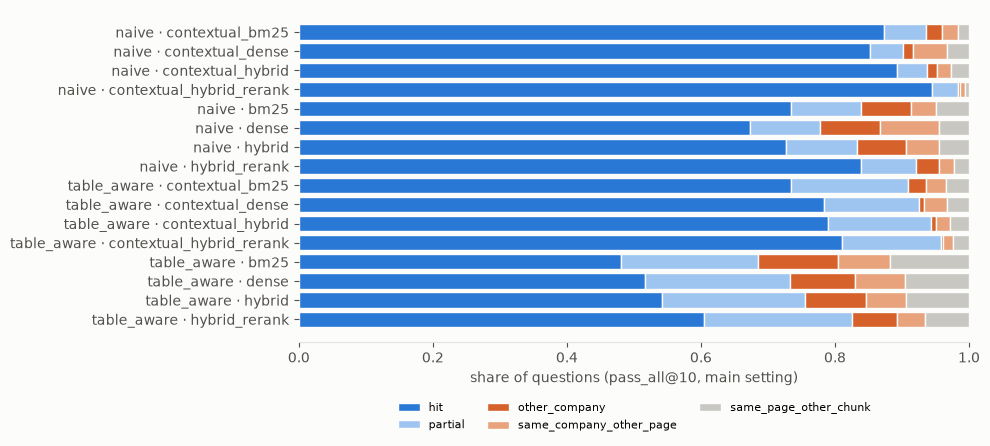

In [3]:
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
COLORS = {"hit": "#2a78d6", "partial": "#9ec5f0", "other_company": "#d6612a",
          "same_company_other_page": "#e8a37c", "same_page_other_chunk": "#c9c7c1"}
fig, ax = plt.subplots(figsize=(10, 4.6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
labels = [f"{s} · {c}" for s, c in shares.index]
left = pd.Series(0.0, index=shares.index)
for m in FAILURE_MODES:
    ax.barh(labels, shares[m], left=left, color=COLORS[m], label=m, edgecolor=SURFACE, linewidth=1)
    left += shares[m]
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("share of questions (pass_all@10, main setting)", color=INK2)
ax.legend(ncol=3, fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15))
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(colors=INK2)
plt.tight_layout(); plt.show()

**How to read it.**

- Under `naive`, the reranker mainly removes *wrong-company* and *wrong-page* misses: it reads the
  query and the chunk together, so it notices that a chunk about the right metric belongs to the
  wrong issuer or year.
- Under `table_aware`, the dominant failure is `partial`: the right page is found, but not all of
  its gold rows make the top 10. That is the next section.

## 2. Granularity: why table_aware loses

`table_aware` makes one chunk per table row, so a question's gold facts are spread over more
chunks, and `pass_all` needs **all** of them. `pass_any@10` (at least one gold fact found) shows
whether the right place was reached at all.

In [4]:
g = by_gold[(by_gold.setting == "main") & (by_gold.config == "hybrid_rerank")]
g.pivot_table(index="n_gold_bucket", columns="strategy", values=["n", "pass_all@10", "pass_any@10"]).round(3)

n             pass_all@10             pass_any@10  \
strategy       naive table_aware       naive table_aware       naive   
n_gold_bucket                                                          
1              912.0       607.0       0.909       0.865       0.909   
2              224.0       427.0       0.585       0.368       0.969   
3+              11.0       113.0       0.273       0.106       1.000   

                           
strategy      table_aware  
n_gold_bucket              
1                   0.865  
2                   0.789  
3+                  0.752

**Reading.** Two effects add up:

1. **More questions have several gold chunks** under `table_aware` (column `n`): two gold rows that
   sat in the same 200-token window under `naive` are now two separate chunks.
2. **Each multi-fact question is harder**: every extra gold chunk is one more chance to miss.

Even with a single gold fact, `table_aware` is a little behind. An isolated row such as
`2015 | revenue: 1,234` says nothing about which company or which table it comes from. That is
exactly the gap contextual retrieval targets (section 4).

## 3. Dense misses that BM25 rescues

Number of questions where BM25 finds every gold fact in the top 10 and dense does not:

In [5]:
rescues.groupby(["strategy", "setting"]).size().unstack("setting")

setting,company_filter,main,raw_question
strategy,,,
naive,60,148,187
table_aware,51,66,78


Three examples (seed-fixed sample, `naive`, main setting). For each: the question, the gold
chunk that **dense missed** (with its BM25 rank), and the chunk dense ranked first. When dense found
some gold facts but not all, the miss is `partial`.

In [6]:
def short(text, n=320):
    text = " ".join(text.split())
    return text if len(text) <= n else text[:n] + " …"

corpus = corpora["naive"]
runs = per_query[(per_query.strategy == "naive") & (per_query.setting == "main")].set_index(["config", "qid"])
sample = rescues[(rescues.strategy == "naive") & (rescues.setting == "main")].sample(3, random_state=0)
for qid in sample.qid:
    q = questions[qid]
    dense = json.loads(runs.loc[("dense", qid), "ranked_top10"])
    bm25 = json.loads(runs.loc[("bm25", qid), "ranked_top10"])
    gold = corpus.gold_sets(q.page_id, q.gold_keys)
    missed = next(g for g in gold if not g & set(dense))
    chunk = min(missed, key=lambda i: bm25.index(i) if i in bm25 else 99)
    found = sum(bool(g & set(dense)) for g in gold)
    print(f"QUESTION   [{bench.company(q.page_id)}] {q.question}")
    print(f"           dense found {found}/{len(gold)} gold chunks in its top 10")
    print(f"MISSED     (BM25 rank {bm25.index(chunk) + 1}) {short(corpus.chunks[chunk].text)}")
    print(f"DENSE #1   ({bench.company(corpus.chunks[dense[0]].page_id)}) {short(corpus.chunks[dense[0]].text)}")
    print("-" * 100)

QUESTION   [American Tower] what is the net change in the balance of unrecognized tax benefits during 2015?
           dense found 1/2 gold chunks in its top 10
MISSED     (BM25 rank 6) the lapse of statute of limitations and effective settlements | -3168 ( 3168 ) | -3504 ( 3504 ) | -5349 ( 5349 ) balance at december 31 | $ 107551 | $ 28114 | $ 31947 during the years ended december 31 , 2016 , 2015 and 2014 , the statute of limitations on certain unrecognized tax benefits lapsed and certain positions  …
DENSE #1   (American Tower) american tower corporation and subsidiaries notes to consolidated financial statements the company expects the unrecognized tax benefits to change over the next 12 months if certain tax matters ultimately settle with the applicable taxing jurisdiction during this timeframe , or if the applicable statute of limitations  …
----------------------------------------------------------------------------------------------------
QUESTION   [Adobe] the combined amount 

**What to look for.** Dense embeddings capture the *topic* ("revenue growth", "debt maturity")
but blur exact tokens: a year, a line-item name, a figure. BM25 matches those tokens literally.
FinQA questions are full of them, which is why BM25 alone beats dense under `naive` chunking, and
why hybrid search keeps both.

## 4. What contextualization changes

This section fills in once `make b2-contextual` has run: the same failure modes, with the
contextualized retrievers next to the plain ones.

In [7]:
ctx = modes[(modes.setting == "main") & modes.config.str.startswith("contextual_")]
if ctx.empty:
    print("No contextual results yet: run `make b2-contextualize b2-contextual b2-report b2-analysis`.")
else:
    pairs = main.loc[:, list(FAILURE_MODES)]
    pairs = pairs[pairs.index.get_level_values("config").isin(["hybrid_rerank", "contextual_hybrid_rerank"])]
    display(pairs)

hit  partial  other_company  \
strategy    config                                                   
naive       contextual_hybrid_rerank  1083       46              2   
            hybrid_rerank              963       94             39   
table_aware contextual_hybrid_rerank   930      169              3   
            hybrid_rerank              694      253             77   

                                      same_company_other_page  \
strategy    config                                              
naive       contextual_hybrid_rerank                        9   
            hybrid_rerank                                  25   
table_aware contextual_hybrid_rerank                       18   
            hybrid_rerank                                  47   

                                      same_page_other_chunk  
strategy    config                                           
naive       contextual_hybrid_rerank                      7  
            hybrid_rerank                                26  
table_aware contextual_hybrid_rerank                     27  
            hybrid_rerank                                76